In [ ]:
import numpy as np
import matplotlib.pyplot as plt
def rng(m=2**32, a=1103515245, c=12345):
    rng.current = (a * rng.current + c) % m
    return rng.current / m

#setting the seed
rng.current = 1
samples = [rng() for _ in range(1000)]


Задача 1


In [17]:
def serial_test(samples, k=4):
    samples = np.array(samples) 
    if samples.ndim == 1:
        samples = samples.reshape(-1, 2)
    n = len(samples)
    #Разбиваем на интервалы (бины): умножаем на k и берем целую часть
    bins_x = np.clip((samples[:, 0] * k).astype(int), 0, k - 1)
    bins_y = np.clip((samples[:, 1] * k).astype(int), 0, k - 1)
    #Создаем матрицу частот k x k
    observed_freqs = np.zeros((k, k))
    #Считаем частоты попадания в каждую ячейку
    for i in range(n):
        observed_freqs[bins_x[i], bins_y[i]] += 1
    expected_freq = n / (k * k)
    #Хи-квадрат
    chi_square_stat = np.sum((observed_freqs - expected_freq) ** 2 / expected_freq)
    df = k**2 - 1
    return chi_square_stat, df, observed_freqs

#Задаем k 
k_val = 4
samples_2d = np.array(samples).reshape(-1, 2)
#Запускаем тест
chi2_stat, degrees_of_freedom, freqs = serial_test(samples_2d, k=k_val)
print(f"Статистика Хи-квадрат: {chi2_stat:.4f}")
print(f"Степени свободы: {degrees_of_freedom}")
print(f"Матрица частот:\n{freqs}")

Статистика Хи-квадрат: 13.6000
Степени свободы: 15
Матрица частот:
[[40. 28. 28. 25.]
 [29. 30. 29. 33.]
 [25. 26. 30. 28.]
 [37. 38. 32. 42.]]


Задача 2

In [12]:
import numpy as np

def permutation_test(samples, d=3):
    samples = np.asarray(samples)
    n = len(samples)
    num_series = n // d
    samples = samples[:num_series * d]
    #Разбиваем на серии размера d
    series = samples.reshape(num_series, d)
    patterns = [tuple(np.argsort(row)) for row in series]
    unique, counts = np.unique(patterns, axis=0, return_counts=True)
    freq_dict = {tuple(u): c for u, c in zip(unique, counts)}
    import math
    num_patterns = math.factorial(d)
    expected_freq = num_series / num_patterns
    
    #Хи-квадрат
    chi_square_stat = 0
    for pattern in freq_dict.values():
        chi_square_stat += (pattern - expected_freq) ** 2 / expected_freq
        
    missing_patterns = num_patterns - len(freq_dict)
    chi_square_stat += missing_patterns * (0 - expected_freq) ** 2 / expected_freq
    
    #Степени свободы: количество паттернов минус 1
    df = num_patterns - 1
    
    return chi_square_stat, df, freq_dict

#Применяем
chi2_stat, df, freqs = permutation_test(samples, d=3)

print(f"Статистика Хи-квадрат: {chi2_stat:.4f}")
print(f"Степени свободы: {df}")
print(f"Частоты паттернов (ключ - порядок индексов):")
for k, v in sorted(freqs.items()):
    print(f"  {k}: {v}")

Статистика Хи-квадрат: 4.8559
Степени свободы: 5
Частоты паттернов (ключ - порядок индексов):
  (np.int64(0), np.int64(1), np.int64(2)): 49
  (np.int64(0), np.int64(2), np.int64(1)): 62
  (np.int64(1), np.int64(0), np.int64(2)): 61
  (np.int64(1), np.int64(2), np.int64(0)): 60
  (np.int64(2), np.int64(0), np.int64(1)): 57
  (np.int64(2), np.int64(1), np.int64(0)): 44


Задача 3

In [ ]:
def rng_bad(m=2**31, a=65539, c=0):
    rng_bad.current = (a * rng_bad.current + c) % m
    return rng_bad.current / m
rng_bad.current = 1
rng.current = 1
random_bad = np.array([rng_bad() for _ in range(30000)])
random_good = np.array([rng() for _ in range(30000)])
#Восстанавливаем целые числа(умножаем обратно на m)
bad_ints = np.array([int(x * 2**31) for x in random_bad])
good_ints = np.array([int(x * 2**32) for x in random_good])

#Берем остаток от деления на 4(ловим последние два бита)
bad_mod4 = bad_ints % 4
good_mod4 = good_ints % 4

#Тест
chi2_b, df, _ = serial_test(bad_mod4, k=2)
chi2_g, _, _ = serial_test(good_mod4, k=2)

print(f"Плохой генератор (x % 4): chi2 = {chi2_b:.1f}, df = {df}")
print(f"Хороший генератор (x % 4): chi2 = {chi2_g:.1f}, df = {df}")

Плохой генератор (x % 4): chi2 = 45000.0, df = 3
Хороший генератор (x % 4): chi2 = 15000.0, df = 3


Задача 4

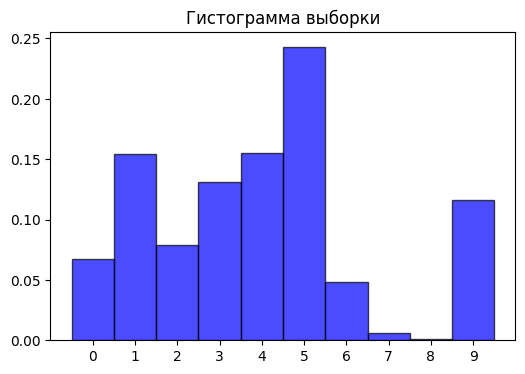

In [40]:
import numpy as np
import matplotlib.pyplot as plt

weights = np.array([0.12, 0.3, 0.167, 0.24, 0.31, 0.54, 0.111, 0.02, 0.001, 0.2])
digits = np.arange(10)

#Сортируем веса
sort_idx = np.argsort(weights)
sorted_weights = weights[sort_idx]

#Нормируем
cum_weights = np.cumsum(sorted_weights / sorted_weights.sum())

u = np.random.rand(1000)
bin_indices = np.searchsorted(cum_weights, u)

#Восстанавливаем исходные цифры по индексам сортировки
samples = digits[sort_idx[bin_indices]]

#Строим гистограмму
fig = plt.figure(figsize=(6, 4))
fig.patch.set_facecolor('xkcd:white')
plt.hist(samples, bins=np.arange(11) - 0.5, density=True, alpha=0.7, color='b', edgecolor='black')
plt.xticks(digits)
plt.title("Гистограмма выборки")
plt.show()

Задача 5

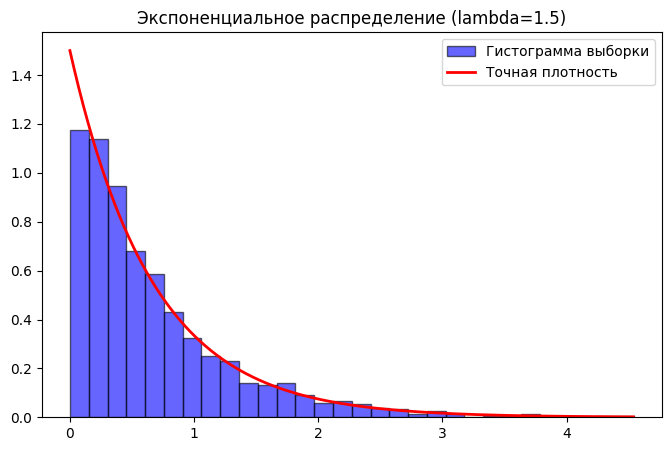

In [ ]:
lam = 1.5
size = 1000

#Генерируем равномерную выборку
u = np.random.rand(size)

#Inverse transform method
samples = -np.log(u) / lam

#Строим графики
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('xkcd:white')

#Выборочная гистограмма
ax.hist(samples, bins=30, density=True, alpha=0.6, color='b', edgecolor='black', label='Гистограмма выборки')

#Точный график плотности: f(x) = lambda * exp(-lambda * x)
x_vals = np.linspace(0, max(samples), 1000)
pdf_vals = lam * np.exp(-lam * x_vals)
ax.plot(x_vals, pdf_vals, 'r-', lw=2, label='Точная плотность')

ax.set_title(f'Экспоненциальное распределение (lambda={lam})')
ax.legend()
plt.show()

Задача 6

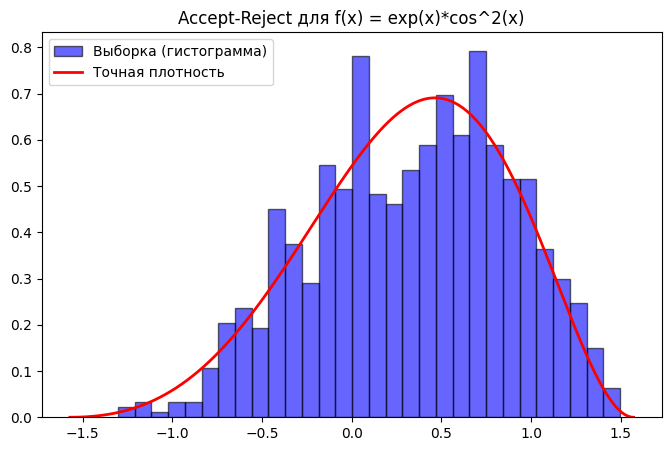

In [32]:
#Задаем функцию плотности
def f(x):
    return np.exp(x) * np.cos(x)**2

#Границы отрезка
a, b = -np.pi/2, np.pi/2
x_grid = np.linspace(a, b, 10000)
max_f = np.max(f(x_grid)) 
#Берем чуть с запасом для надежности
M = max_f * 1.05 

#Генерируем 1000 точек методом Accept-Reject
N = 1000
samples = []
num_trials = 3000
x_trials = np.random.uniform(a, b, num_trials)
y_trials = np.random.uniform(0, M, num_trials)

#Оставляем только те точки, которые попали под график
accepted_mask = y_trials <= f(x_trials)
samples = x_trials[accepted_mask]

#Обрезаем до 1000, если приняли больше
samples = samples[:1000]

#Построение графиков
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('xkcd:white')

#Выборочная гистограмма (density=True нормирует площадь на 1)
ax.hist(samples, bins=30, density=True, alpha=0.6, color='b', edgecolor='black', label='Выборка (гистограмма)')
from scipy.integrate import quad
integral_val, _ = quad(f, a, b)
x_plot = np.linspace(a, b, 500)
pdf_exact = f(x_plot) / integral_val

ax.plot(x_plot, pdf_exact, 'r-', lw=2, label='Точная плотность')

ax.set_title('Accept-Reject для f(x) = exp(x)*cos^2(x)')
ax.legend()
plt.show()

Задача 7

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


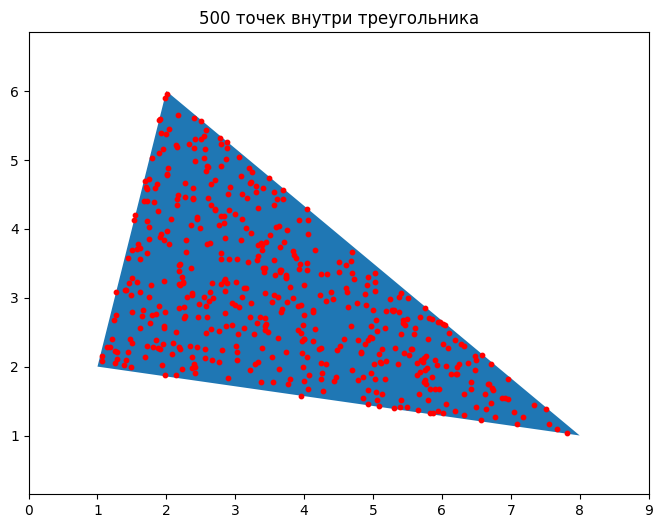

In [34]:
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
A = np.array([1, 2])
B = np.array([2, 6])
C = np.array([8, 1])

#Генерируем 500 случайных чисел для весов
u1 = np.random.rand(500)
u2 = np.random.rand(500)

# Применяем формулу барицентрических координат
w_A = 1 - np.sqrt(u1)
w_B = np.sqrt(u1) * (1 - u2)
w_C = np.sqrt(u1) * u2

#Получаем координаты точек: умножаем веса на координаты вершин и складываем
x_points = w_A * A[0] + w_B * B[0] + w_C * C[0]
y_points = w_A * A[1] + w_B * B[1] + w_C * C[1]

#График
fig = plt.figure(figsize=(8, 6))
fig.patch.set_facecolor('xkcd:white')

#Исходный треугольник
polygon = Polygon(np.array([A, B, C]), closed=True, alpha=0.3, color='blue')
plt.gca().add_collection(PatchCollection([polygon]))

#Наносим точки
plt.scatter(x_points, y_points, color='red', s=10, zorder=2)

plt.axis('equal')
plt.xlim(0, 9)
plt.ylim(0, 7)
plt.title('500 точек внутри треугольника')
plt.show()

Задача 8

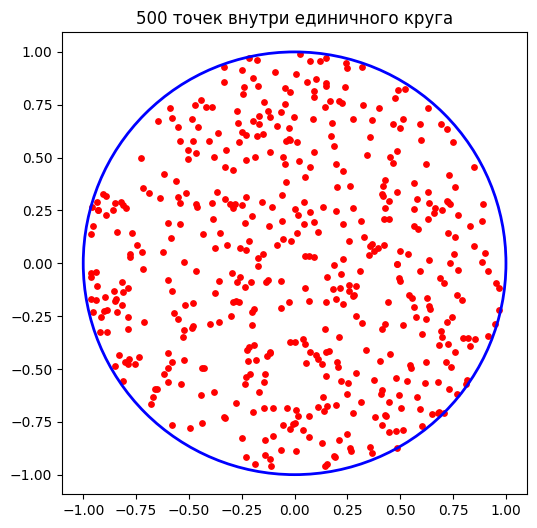

In [41]:
N = 500

#Генерируем равномерные числа
u1 = np.random.rand(N)
u2 = np.random.rand(N)

#Переходим к полярным координатам
theta = 2 * np.pi * u1
r = np.sqrt(u2)

x = r * np.cos(theta)
y = r * np.sin(theta)

#Построение
fig = plt.figure(figsize=(6, 6))
fig.patch.set_facecolor('xkcd:white')

plt.scatter(x, y, color='red', s=15)

#Граница круга
circle = plt.Circle((0, 0), 1, color='blue', fill=False, linewidth=2)
plt.gca().add_patch(circle)

plt.axis('equal')
plt.title('500 точек внутри единичного круга')
plt.show()

Задача 9

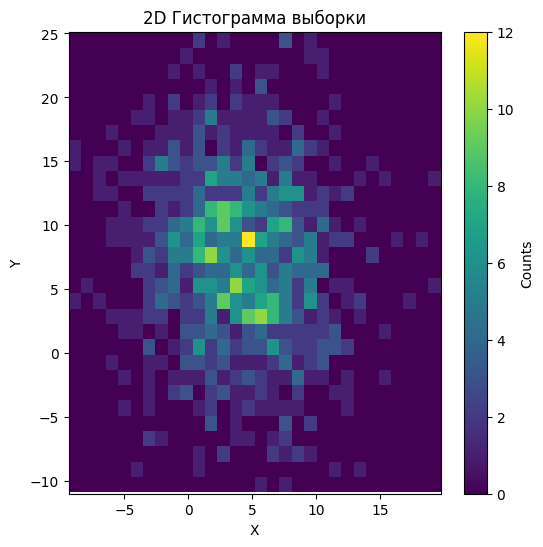

Точное среднее: [4 7]
Выборочное среднее: [4.03575656 7.36249838]

Точная ковариационная матрица:
 [[20 -4]
 [-4 40]]
Выборочная ковариационная матрица:
 [[18.72587312 -2.47569331]
 [-2.47569331 41.24515456]]


In [37]:
N = 1000
#Матрица ковариации и среднее
cov_matrix = np.array([[20, -4], [-4, 40]])
mean = np.array([4, 7])

z1 = []
z2 = []

while len(z1) < N:
    v1 = np.random.uniform(-1, 1, N)
    v2 = np.random.uniform(-1, 1, N)
    s = v1**2 + v2**2
    #Оставляем только те, что попали в круг (s < 1) и s != 0
    mask = (s < 1) & (s > 1e-10)
    v1, v2, s = v1[mask], v2[mask], s[mask]
    
    mult = np.sqrt(-2 * np.log(s) / s)
    z1.extend(v1 * mult)
    z2.extend(v2 * mult)

z = np.column_stack((z1[:N], z2[:N]))

#Преобразование к нужному распределению через разложение Холецкого
L = np.linalg.cholesky(cov_matrix)
samples = mean + z @ L.T

fig = plt.figure(figsize=(6, 6))
fig.patch.set_facecolor('xkcd:white')
plt.hist2d(samples[:, 0], samples[:, 1], bins=30, cmap='viridis')
plt.colorbar(label='Counts')
plt.title('2D Гистограмма выборки')
plt.xlabel('X')
plt.ylabel('Y')
plt.axis('equal')
plt.show()

sample_mean = np.mean(samples, axis=0)
sample_cov = np.cov(samples, rowvar=False)

print("Точное среднее:", mean)
print("Выборочное среднее:", sample_mean)
print("\nТочная ковариационная матрица:\n", cov_matrix)
print("Выборочная ковариационная матрица:\n", sample_cov)

Задача 10

In [ ]:
from math import comb
#Вычисление чисел Белла (количество всех разбиений множества из n элементов)
def compute_bell(n):
    B = [0] * (n + 1)
    B[0] = 1
    for i in range(1, n + 1):
        for k in range(i):
            B[i] += comb(i - 1, k) * B[k]
    return B
#Рекурсивная генерация равномерного случайного разбиения
def random_partition(elements, B):
    n = len(elements)
    if n == 0:
        return []
    probs = [comb(n - 1, k - 1) * B[n - k] for k in range(1, n + 1)]
    probs = np.array([p / B[n] for p in probs])
    k = np.random.choice(range(1, n + 1), p=probs)
    chosen = np.random.choice(elements[:-1], size=k-1, replace=False)
    block = list(chosen) + [elements[-1]]
    
    #Оставшиеся элементы разбиваем рекурсивно
    remaining = [x for x in elements if x not in block]
    return [block] + random_partition(remaining, B)

#Точное значение для сравнения
def stirling_second(n):
    S = [[0] * (n + 1) for _ in range(n + 1)]
    S[0][0] = 1
    for i in range(1, n + 1):
        for j in range(1, i + 1):
            S[i][j] = S[i-1][j-1] + j * S[i-1][j]
    return S
n = 100
B = compute_bell(n)
elements = list(range(n))

#Оценка Монте-Карло
n_samples = 1000
block_counts = []
for _ in range(n_samples):
    partition = random_partition(elements, B)
    block_counts.append(len(partition))

#Точное вычисление
S = stirling_second(n)
B_n = sum(S[n])
exact_mean = sum(k * S[n][k] for k in range(1, n + 1)) / B_n

print(f"Точное ожидаемое число подмножеств: {exact_mean:.2f}")
print(f"Выборочное среднее (n={n_samples}): {np.mean(block_counts):.2f}")

Точное ожидаемое число подмножеств: 28.63
Выборочное среднее (n=1000): 28.66
